
# COU 07506 Digital Signal Processing
## Week 2 — Lab 1A: Sampling, Aliasing and Quantization

**Name:** RAHMA ABDALLAH VUMBI

**Registration Number:** 250242499374

**Class:** BENG24COE-3


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)


### . PRE-LAB PREPARATION


Question A: A 7 kHz tone is sampled at 10 kHz. What frequency appears?

Nyquist frequency:

fN=fs\ 2= 10 \ 2 = 5kHz

"bacause 7 kHz is larger than 5 kHz, there will be aliasing."

falas = |7-10| = 3kHz

Answer: 3 kHz.


Question B: Compute Δ and theoretical SQNR for an 8-bit quantizer with ±1 V range.

Quantization step:

 🔺= 2Xm \ 2 exp B = 2(1) \ 2 EXP 8 = 2\256

 🔺= 0.0078125V

Theoretical SQNR:

SQNR=6.02B+1.76

=6.02(8)+1.76

SQNR=49.92dB

Task 2.1 — Aliasing of a Sinusoid


Cell 1 — Original example

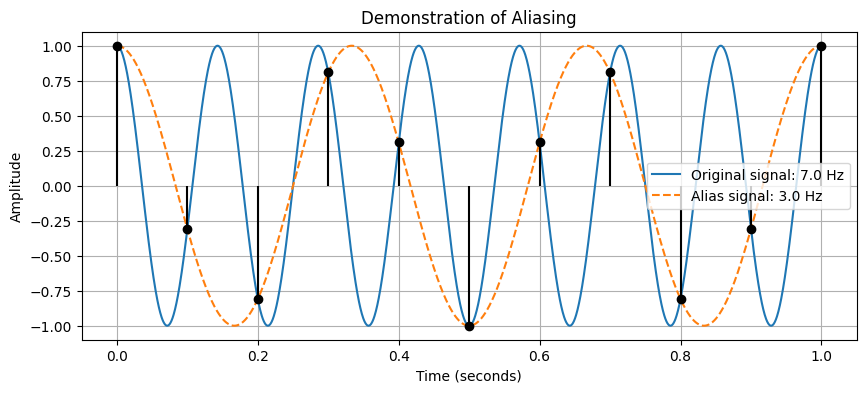

Alias frequency: 3.0 Hz


In [2]:

f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)

n = np.arange(0, int(fs) + 1)
tn = n / fs

f_alias = abs(f0 - fs*round(f0/fs))

plt.figure(figsize=(10, 4))

plt.plot(t, np.cos(2*np.pi*f0*t),
         label=f"Original signal: {f0} Hz")

plt.plot(t, np.cos(2*np.pi*f_alias*t), "--",
         label=f"Alias signal: {f_alias} Hz")

plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Demonstration of Aliasing")
plt.legend()
plt.grid(True)
plt.show()

print("Alias frequency:", f_alias, "Hz")


Cell 2 — Repeat for different sampling frequencies

In [3]:

f0 = 7.0
sampling_rates = [10, 12, 14, 20]

alias_results = []

for fs in sampling_rates:
    f_alias = abs(f0 - fs*round(f0/fs))

    alias_results.append([fs, fs/2, f_alias])

print("Sampling Frequency | Nyquist Frequency | Alias Frequency")

for row in alias_results:
    print(row)


Sampling Frequency | Nyquist Frequency | Alias Frequency
[10, 5.0, 3.0]
[12, 6.0, 5.0]
[14, 7.0, 7.0]
[20, 10.0, 7.0]


Task 2.2 — Hear Aliasing

Cell 1 — Loading my  recording

In [4]:

import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)
    x = x / np.max(np.abs(x))

else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

print("Original sampling rate:", fs, "Hz")
print("Original samples:", len(x))


Original sampling rate: 44100 Hz
Original samples: 132300


Cell 2 — Performing downsampling

In [5]:

for k in [2, 4, 8]:

    naive = x[::k]

    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs // k

    print("\nDownsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    print("Naive version:")
    display(Audio(naive, rate=new_fs))

    print("Filtered version:")
    display(Audio(proper, rate=new_fs))



Downsampling factor: 2
New sampling rate: 22050 Hz
Naive version:


Filtered version:



Downsampling factor: 4
New sampling rate: 11025 Hz
Naive version:


Filtered version:



Downsampling factor: 8
New sampling rate: 5512 Hz
Naive version:


Filtered version:



### Observation — Task 2.2

The naïve downsampled audio may contain aliasing, which can make the sound distorted or unclear. The properly decimated audio uses a low-pass anti-aliasing filter before reducing the samples, helping to preserve the original sound and reduce aliasing.


Task 2.3 — A Uniform Quantizer


Cell 1 — Create quantizer function

In [7]:

def quantize(x, bits, full_scale=1.0):

    delta = 2*full_scale / 2**bits

    q = np.round(x/delta)*delta

    return np.clip(q, -full_scale, full_scale-delta)


Cell 2 — Generate original signal

In [8]:

fs = 8000

t = np.arange(0, 0.01, 1/fs)

x = 0.99*np.sin(2*np.pi*300*t)

xq = quantize(x, 3)

print("Original signal samples:")
print(x)

print("\nQuantized signal samples:")
print(xq)


Original signal samples:
[ 0.00000000e+00  2.31110910e-01  4.49450595e-01  6.42953568e-01
  8.00926824e-01  9.14640737e-01  9.77811457e-01  9.86948160e-01
  9.41545951e-01  8.44113763e-01  7.00035713e-01  5.17273579e-01
  3.05926824e-01  7.76745048e-02 -1.54870120e-01 -3.78856598e-01
 -5.81907400e-01 -7.52801906e-01 -8.82096459e-01 -9.62646221e-01
 -9.90000000e-01 -9.62646221e-01 -8.82096459e-01 -7.52801906e-01
 -5.81907400e-01 -3.78856598e-01 -1.54870120e-01  7.76745048e-02
  3.05926824e-01  5.17273579e-01  7.00035713e-01  8.44113763e-01
  9.41545951e-01  9.86948160e-01  9.77811457e-01  9.14640737e-01
  8.00926824e-01  6.42953568e-01  4.49450595e-01  2.31110910e-01
  3.63720099e-16 -2.31110910e-01 -4.49450595e-01 -6.42953568e-01
 -8.00926824e-01 -9.14640737e-01 -9.77811457e-01 -9.86948160e-01
 -9.41545951e-01 -8.44113763e-01 -7.00035713e-01 -5.17273579e-01
 -3.05926824e-01 -7.76745048e-02  1.54870120e-01  3.78856598e-01
  5.81907400e-01  7.52801906e-01  8.82096459e-01  9.62646221e-01


Cell 3 — Plot quantized signal


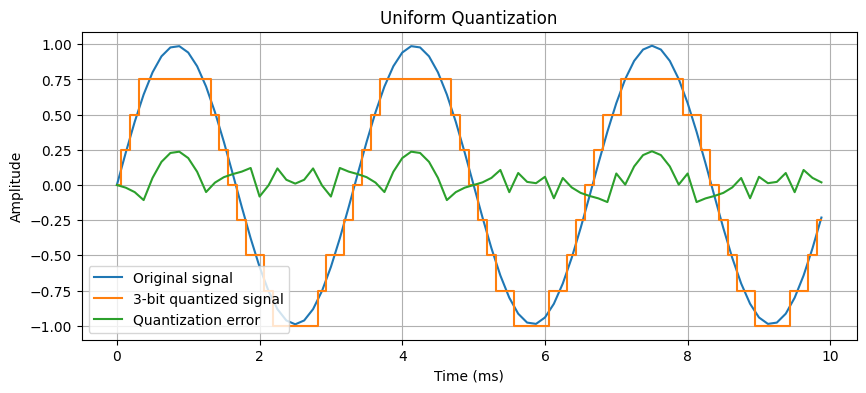

In [9]:

plt.figure(figsize=(10, 4))

plt.plot(t*1e3, x, label="Original signal")

plt.step(t*1e3, xq, where="mid",
         label="3-bit quantized signal")

plt.plot(t*1e3, x-xq, label="Quantization error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Uniform Quantization")
plt.legend()
plt.grid(True)

plt.show()


Task 2.4 — Verify the 6 dB-per-bit Rule

Formula:
\[
SQNR=10\log_{10}
{\sum x^2}\{\sum e^2}


Cell 1 — Calculate measured SQNR

In [10]:

bits = np.arange(2, 17, 2)

meas = []

for B in bits:

    xq = quantize(x, B)

    error = x - xq

    sqnr = 10*np.log10(
        np.sum(x**2)/np.sum(error**2)
    )

    meas.append(sqnr)

print("Bits | Measured SQNR")

for B, value in zip(bits, meas):
    print(B, "|", round(value, 2), "dB")


Bits | Measured SQNR
2 | 9.6 dB
4 | 23.58 dB
6 | 36.81 dB
8 | 48.93 dB
10 | 62.81 dB
12 | 72.84 dB
14 | 88.13 dB
16 | 98.91 dB


Cell 2 — Compare with theoretical SQNR

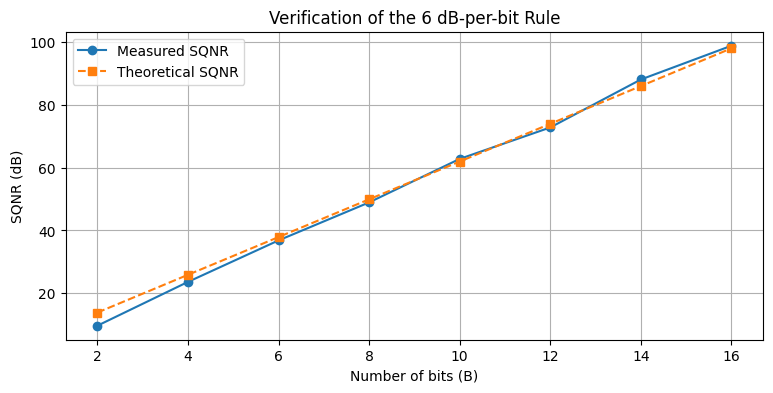

In [11]:

theoretical = 6.02*bits + 1.76

plt.figure(figsize=(9, 4))

plt.plot(bits, meas, "o-", label="Measured SQNR")

plt.plot(bits, theoretical, "s--",
         label="Theoretical SQNR")

plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Verification of the 6 dB-per-bit Rule")

plt.legend()
plt.grid(True)
plt.show()


Task 2.5 — Quantize  the Voice

Cell 1 — Load recording

In [12]:

fname = "my_voice.wav"

if os.path.exists(fname):

    fs, voice = wavfile.read(fname)

    if voice.ndim > 1:
        voice = voice.mean(axis=1)

    voice = voice.astype(float)
    voice = voice / np.max(np.abs(voice))

else:

    fs = 44100
    t = np.arange(0, 3, 1/fs)
    voice = 0.5*signal.chirp(t, 200, 3, 15000)

print("Sampling frequency:", fs)
print("Number of samples:", len(voice))


Sampling frequency: 44100
Number of samples: 132300


Cell 2 — Quantize and calculate SQNR

In [13]:

for B in [4, 8, 12]:

    voice_q = quantize(voice, B)

    error = voice - voice_q

    sqnr = 10*np.log10(
        np.sum(voice**2)/np.sum(error**2)
    )

    print("\nQuantization bits:", B)
    print("SQNR:", round(sqnr, 2), "dB")

    display(Audio(voice_q, rate=fs))



Quantization bits: 4
SQNR: 20.36 dB



Quantization bits: 8
SQNR: 44.05 dB



Quantization bits: 12
SQNR: 68.01 dB



Speech has varying amplitude and is not always a full-scale signal. Some speech samples have very small amplitudes, so quantization noise becomes more significant compared with the signal power. Therefore, the measured SQNR of speech is usually lower than that of a full-scale sinusoidal signal using the same number of bits.



## AI-use Statement

AI tools used: ChatGPT.

Used for: Understanding sampling, aliasing, quantization and Python code.

How I verified the output: I ran the Python programs in Google Colab, checked the alias frequencies against the expected calculations and compared measured SQNR with theoretical SQNR.
